<a href="https://colab.research.google.com/github/shalaniupekshani/EN3160-Assignment-3-on-Neural-Networks/blob/main/A02_230659H.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN3160 Assignment 3 on Neural Networks

Index No: 230659H

Name: Upekshani T. S.



Github Link: [https://github.com/shalaniupekshani/EN3160-Assignment-3-on-Neural-Networks](https://github.com/shalaniupekshani/EN3160-Assignment-3-on-Neural-Networks)

# Question 01 - Two-Layer Network (100 Hidden Nodes, Sigmoid, Cross-Entropy)

In [111]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from torch.optim import lr_scheduler
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import time
import copy
import os

In [6]:
# Data Loading
transform=transforms.Compose([transforms.ToTensor(),transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))])
batch_size=50
trainset=torchvision.datasets.CIFAR10(root="./data",train=True,download=True,transform=transform)
trainloader=torch.utils.data.DataLoader(trainset,batch_size=batch_size,shuffle=True,num_workers=2)
testset=torchvision.datasets.CIFAR10(root="./data",train=False,download=True,transform=transform)
testloader=torch.utils.data.DataLoader(testset,batch_size=batch_size,shuffle=False,num_workers=2)
classes=('plane','car','bird','cat','deer','dog','frog','horse','ship','truck')

100%|██████████| 170M/170M [57:42<00:00, 49.2kB/s]


In [112]:
# Define Network Parameters
torch.manual_seed(0)
Din=3*32*32 #Input size (Flattened CIFAR-10 image size)
K=10 #Output size (Number of classes in CIFAR-10)
H=100 #middle layer with 100 nodes
#std=1e-5

# Initialize weights and biases
#w=torch.randn(Din,K)*std #One layer: directly map input to output
#b=torch.zeros(K)
w1=torch.randn(Din,H)/(Din**0.5)   # std ~ 0.018
b1=torch.zeros(H)
w2=torch.randn(H,K)/(H**0.5)       # std = 0.1
b2=torch.zeros(K)

# Hyperparameters
iterations=10
#lr=2e-6 #learning rate
lr=0.1 # since here we reduce number of epochs
lr_decay=0.9 #learning rate decay
reg=0 #regularization
loss_history=[]

In [113]:
# Training Loop
for t in range(iterations):
    running_loss=0.0
    for i,data in enumerate(trainloader,0):
        #Get inputs and labels
        inputs,labels=data
        Ntr=inputs.shape[0] # Batch size
        x_train=inputs.view(Ntr,-1) #Flatten input to (Ntr,Din)
        y_train_onehot=nn.functional.one_hot(labels,K).float() # Convert labels to one hot

        #Forward pass
        #y_pred=x_train.mm(w)+b #output layer activation
        # Hidden Layer
        z1=x_train.mm(w1)+b1
        h=torch.sigmoid(z1)
        # Output layer
        y_pred=h.mm(w2)+b2

        #Loss calculation (mean square error with regularization)
        #loss=((1/Ntr)*torch.sum((y_pred-y_train_onehot)**2)+reg*torch.sum(w**2))
        #MSE Loss
        #loss=((1/Ntr)*torch.sum((y_pred-y_train_onehot)**2)+reg*(torch.sum(w1**2)+torch.sum(w2**2)))

        # Cross Entropy Loss
        loss=nn.functional.cross_entropy(y_pred,labels)+reg*(torch.sum(w1**2)+torch.sum(w2**2))
        loss_history.append(loss.item())
        running_loss+=loss.item()

        #Backpropagation
        #dy_pred=(2.0/Ntr)*(y_pred-y_train_onehot)
        #Backpropagation - logit
        probs=torch.softmax(y_pred,dim=1)
        dy_pred=(probs-y_train_onehot)/Ntr

        #dw=x_train.t().mm(dy_pred)+reg*w
        #db=dy_pred.sum(dim=0)

        # output layer
        dw2=h.t().mm(dy_pred)+2*reg*w2
        db2=dy_pred.sum(dim=0)
        #Hidden layer
        dh=dy_pred.mm(w2.t())
        dz1=dh*h*(1-h)
        dw1=x_train.t().mm(dz1)+2*reg*w1
        db1=dz1.sum(dim=0)

        #Parameter update
        #w-=lr*dw
        #b-=lr*db
        with torch.no_grad():
            w1-=lr*dw1
            b1-=lr*db1
            w2-=lr*dw2
            b2-=lr*db2

    # Print loss for every epoch
    if t%1==0:
        print(f"Epoch_{t+1}/{iterations},_Loss:_{running_loss/len(trainloader)}")
    #Learning rate decay
    lr*=lr_decay

Epoch_1/10,_Loss:_1.8086126502752304
Epoch_2/10,_Loss:_1.6752910828590393
Epoch_3/10,_Loss:_1.6159888243675231
Epoch_4/10,_Loss:_1.570524916768074
Epoch_5/10,_Loss:_1.532432309985161
Epoch_6/10,_Loss:_1.4983992619514466
Epoch_7/10,_Loss:_1.470320559501648
Epoch_8/10,_Loss:_1.4440142967104912
Epoch_9/10,_Loss:_1.4208519881367683
Epoch_10/10,_Loss:_1.4006456015110016


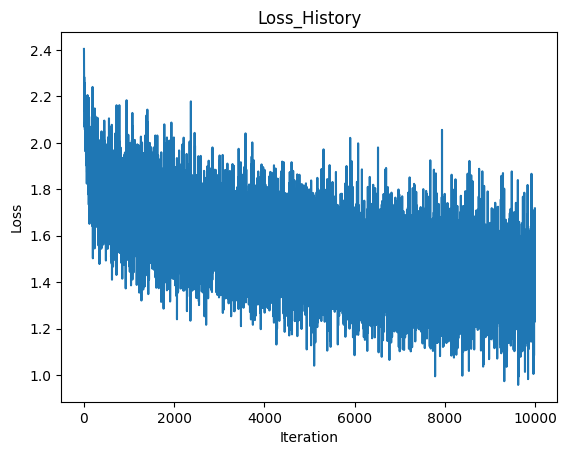

In [114]:
#Plotting Loss history
plt.plot(loss_history)
plt.title("Loss_History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

In [115]:
# calculate accuracy on Training Set
correct_train=0
total_train=0
with torch.no_grad():
    for data in trainloader:
        inputs,labels=data
        Ntr=inputs.shape[0]
        x_train=inputs.view(Ntr,-1)
        y_train_onehot=nn.functional.one_hot(labels,K).float()

        #Forward pass
        h=torch.sigmoid(x_train.mm(w1)+b1)
        y_train_pred=h.mm(w2)+b2
        predicted_train=torch.argmax(y_train_pred,dim=1)
        total_train+=labels.size(0)
        correct_train+=(predicted_train==labels).sum().item()

train_acc=100*correct_train/total_train
print(f"Training_accuracy: {train_acc:.2f}%")

Training_accuracy: 53.31%


In [116]:
# Calculate accuracy on Test Set
correct_test=0
total_test=0
with torch.no_grad():
    for data in testloader:
        inputs,labels=data
        Nte=inputs.shape[0]
        x_test=inputs.view(Nte,-1)
        y_test_onehot=nn.functional.one_hot(labels,K).float()

        # Forward Pass
        h=torch.sigmoid(x_test.mm(w1)+b1)
        y_test_pred=h.mm(w2)+b2
        predicted_test=torch.argmax(y_test_pred,dim=1)
        total_test+=labels.size(0)
        correct_test+=(predicted_test==labels).sum().item()

test_acc=100*correct_test/total_test
print(f"Test_accuracy: {test_acc:.2f}%")

Test_accuracy: 48.46%


## Results and Discussion


*   A two-layer neural network was implemented by adding a hidden layer containing 100 neurons with sigmoid activation to the original single-layer network.
*   Cross-entropy loss was used for classification by replacing mean squared error, and the gradients were calculated manually using backpropagation. The network was trained on the CIFAR-10 dataset for 10 epochs.
*   The average training loss decreased from 1.809 in epoch 1 to 1.400 in epoch 10.
*  The resulting training accuracy was 53.31%, and the test accuracy was 48.46%. The gap of about 4.85% indicates mild overfitting.
*   The first run, with an initial weight scale of 1e-5 and a learning rate of 2e-6, did not learn at all, the loss stayed at ln(10) ≈ 2.303 and accuracy was 10%. This was because the hidden activations were all about 0.5 and the gradients to the first layer vanished, so a larger initialization scale and learning rate (0.1) were needed.
*   The accuracy remains limited because flattening the image discards spatial structure.
*   The experiment shows how nonlinear activations, cross-entropy loss and backpropagation enable a multilayer network to learn.





  





# Question 02

## Part a - LeNet-5 Network for MNIST using Pytorch

In [117]:
# Transform images into tensor and normalize
transform=transforms.Compose([transforms.ToTensor(),transforms.Normalize((0.1307,),(0.3081,))])
# Load MNIST dataset
train_dataset=torchvision.datasets.MNIST(root="./data",train=True,download=True,transform=transform)
test_dataset=torchvision.datasets.MNIST(root="./data",train=False,download=True,transform=transform)

# create data loaders
train_loader=DataLoader(train_dataset,batch_size=64,shuffle=True)
test_loader=DataLoader(test_dataset,batch_size=64,shuffle=False)

#Select CPU or GPU
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:",device)

Using device: cpu


Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])


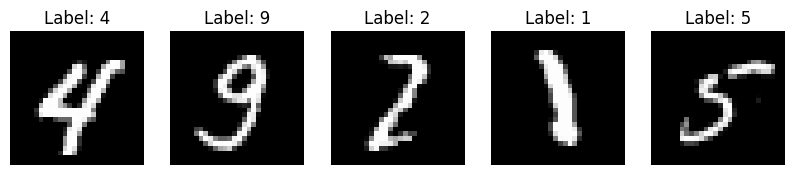

In [118]:
# Examine one batch
images,labels=next(iter(train_loader))
print("Image batch shape:",images.shape)
print("Label batch shape:",labels.shape)

#display first five images
fig,axes=plt.subplots(1,5,figsize=(10,3))
for i in range(5):
    axes[i].imshow(images[i].squeeze(),cmap='gray')
    axes[i].set_title(f"Label: {labels[i].item()}")
    axes[i].axis('off')
plt.show()


In [119]:
# Define the LeNet-5 model
class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5,self).__init__()
        self.features=nn.Sequential(
            #Convolutional layer 1
            nn.Conv2d(1,6,kernel_size=5),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2,stride=2),

            #Convolution layer 2
            nn.Conv2d(6,16,kernel_size=5),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2,stride=2)
        )
        self.classifier=nn.Sequential(
            nn.Linear(16*4*4,120),
            nn.Tanh(),
            nn.Linear(120,84),
            nn.Tanh(),
            nn.Linear(84,10)
        )

    def forward(self,x):
      x=self.features(x)
      x=torch.flatten(x,1)
      x=self.classifier(x)
      return x
model=LeNet5().to(device)
criterion=nn.CrossEntropyLoss()
optimizer=optim.SGD(model.parameters(),lr=0.01,momentum=0.9)
print(model)
print("Total parameters:",sum(p.numel() for p in model.parameters()))

LeNet5(
  (features): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
    (1): Tanh()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Tanh()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
  )
  (classifier): Sequential(
    (0): Linear(in_features=256, out_features=120, bias=True)
    (1): Tanh()
    (2): Linear(in_features=120, out_features=84, bias=True)
    (3): Tanh()
    (4): Linear(in_features=84, out_features=10, bias=True)
  )
)
Total parameters: 44426


In [120]:
def evaluate(model,loaders):
  model.eval()
  correct=0
  total=0
  total_loss=0.0

  with torch.no_grad():
    for images,labels in loaders:
      images,labels=images.to(device),labels.to(device)
      outputs=model(images)
      loss=criterion(outputs,labels)
      total_loss+=loss.item()*labels.size(0)
      _,predicted=torch.max(outputs.data,1)
      total+=labels.size(0)
      correct+=(predicted==labels).sum().item()

  accuracy=100*correct/total
  avg_loss=total_loss/total
  return avg_loss,accuracy

epochs=10
lenet_his={
    'train_loss':[],
    'train_acc':[],
    'test_loss':[],
    'test_acc':[]
  }
for epoch in range(epochs):
  model.train()
  running_loss=0.0
  correct=0
  total=0
  for images,labels in train_loader:
    images,labels=images.to(device),labels.to(device)
    #forward pass
    outputs=model(images)
    loss=criterion(outputs,labels)

    #backpropagation
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    running_loss+=loss.item()*labels.size(0)
    _,predicted=torch.max(outputs,1)

    total+=labels.size(0)
    correct+=(predicted==labels).sum().item()

  train_loss=running_loss/total
  train_accuracy=100*correct/total
  test_loss,test_accuracy=evaluate(model,test_loader)

  lenet_his['train_loss'].append(train_loss)
  lenet_his['train_acc'].append(train_accuracy)
  lenet_his['test_loss'].append(test_loss)
  lenet_his['test_acc'].append(test_accuracy)

  print(f"Epoch {epoch+1}/{epochs}, Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%, Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%")

Epoch 1/10, Train Loss: 0.4064, Train Accuracy: 88.28%, Test Loss: 0.0968, Test Accuracy: 97.01%
Epoch 2/10, Train Loss: 0.0873, Train Accuracy: 97.41%, Test Loss: 0.0584, Test Accuracy: 98.11%
Epoch 3/10, Train Loss: 0.0614, Train Accuracy: 98.19%, Test Loss: 0.0453, Test Accuracy: 98.50%
Epoch 4/10, Train Loss: 0.0496, Train Accuracy: 98.49%, Test Loss: 0.0420, Test Accuracy: 98.60%
Epoch 5/10, Train Loss: 0.0411, Train Accuracy: 98.74%, Test Loss: 0.0346, Test Accuracy: 98.82%
Epoch 6/10, Train Loss: 0.0373, Train Accuracy: 98.83%, Test Loss: 0.0328, Test Accuracy: 98.90%
Epoch 7/10, Train Loss: 0.0327, Train Accuracy: 98.99%, Test Loss: 0.0296, Test Accuracy: 99.07%
Epoch 8/10, Train Loss: 0.0286, Train Accuracy: 99.15%, Test Loss: 0.0293, Test Accuracy: 98.99%
Epoch 9/10, Train Loss: 0.0265, Train Accuracy: 99.20%, Test Loss: 0.0269, Test Accuracy: 99.02%
Epoch 10/10, Train Loss: 0.0232, Train Accuracy: 99.31%, Test Loss: 0.0285, Test Accuracy: 99.00%


In [121]:
train_loss, train_accuracy = evaluate(model, train_loader)
test_loss, test_accuracy = evaluate(model, test_loader)

print("\nFinal Results After 10 Epochs")
print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%")
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%")


Final Results After 10 Epochs
Train Loss: 0.0197, Train Accuracy: 99.41%
Test Loss: 0.0285, Test Accuracy: 99.00%


## Part b - Implementing a Modern Small CNN

In [122]:
class ModernSmallCNN(nn.Module):
    def __init__(self):
        super(ModernSmallCNN, self).__init__()
        self.features = nn.Sequential(
            #Convolution layer 1
            nn.Conv2d(1,32,kernel_size=3,padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2),

            #Convolution layer 2
            nn.Conv2d(32,64,kernel_size=3,padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2),

            #convolution layer 3
            nn.Conv2d(64,128,kernel_size=3,padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Dropout2d(0.25)
        )
        self.classifier=nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*7*7,128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128,10)
        )

    def forward(self,x):
        x=self.features(x)
        x=self.classifier(x)
        return x
model_cnn=ModernSmallCNN().to(device)
criterion_cnn=nn.CrossEntropyLoss()
optimizer_cnn=optim.SGD(model_cnn.parameters(),lr=0.01,momentum=0.9)
print(model_cnn)
print("Total paramenters: ",sum(p.numel() for p in model_cnn.parameters()))

ModernSmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout2d(p=0.25, inplace=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=6272, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Line

In [123]:
epochs=10
cnn_his={
    'train_loss':[],
    'train_acc':[],
    'test_loss':[],
    'test_acc':[]
}
for epoch in range(epochs):
  model_cnn.train()
  running_loss=0.0
  correct=0
  total=0
  for images,labels in train_loader:
    images,labels=images.to(device),labels.to(device)
    #forward pass
    outputs=model_cnn(images)
    loss=criterion_cnn(outputs,labels)

    #backpropagation
    optimizer_cnn.zero_grad()
    loss.backward()
    optimizer_cnn.step()
    running_loss+=loss.item()*labels.size(0)
    _,predicted=torch.max(outputs,1)

    total+=labels.size(0)
    correct+=(predicted==labels).sum().item()

  train_loss=running_loss/total
  train_accuracy=100*correct/total
  test_loss,test_accuracy=evaluate(model_cnn,test_loader)

  cnn_his['train_loss'].append(train_loss)
  cnn_his['train_acc'].append(train_accuracy)
  cnn_his['test_loss'].append(test_loss)
  cnn_his['test_acc'].append(test_accuracy)

  print(f"Epoch {epoch+1}/{epochs}, Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%, Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%")

Epoch 1/10, Train Loss: 0.1749, Train Accuracy: 94.58%, Test Loss: 0.0451, Test Accuracy: 98.52%
Epoch 2/10, Train Loss: 0.0769, Train Accuracy: 97.70%, Test Loss: 0.0356, Test Accuracy: 98.83%
Epoch 3/10, Train Loss: 0.0586, Train Accuracy: 98.30%, Test Loss: 0.0254, Test Accuracy: 99.13%
Epoch 4/10, Train Loss: 0.0478, Train Accuracy: 98.56%, Test Loss: 0.0233, Test Accuracy: 99.21%
Epoch 5/10, Train Loss: 0.0416, Train Accuracy: 98.76%, Test Loss: 0.0270, Test Accuracy: 99.15%
Epoch 6/10, Train Loss: 0.0342, Train Accuracy: 99.02%, Test Loss: 0.0218, Test Accuracy: 99.30%
Epoch 7/10, Train Loss: 0.0304, Train Accuracy: 99.05%, Test Loss: 0.0206, Test Accuracy: 99.40%
Epoch 8/10, Train Loss: 0.0263, Train Accuracy: 99.16%, Test Loss: 0.0206, Test Accuracy: 99.42%
Epoch 9/10, Train Loss: 0.0246, Train Accuracy: 99.24%, Test Loss: 0.0210, Test Accuracy: 99.39%
Epoch 10/10, Train Loss: 0.0215, Train Accuracy: 99.32%, Test Loss: 0.0200, Test Accuracy: 99.36%


In [124]:
train_loss, train_accuracy = evaluate(model_cnn, train_loader)
test_loss, test_accuracy = evaluate(model_cnn, test_loader)

print("\nFinal Results After 10 Epochs")
print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%")
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%")


Final Results After 10 Epochs
Train Loss: 0.0076, Train Accuracy: 99.78%
Test Loss: 0.0200, Test Accuracy: 99.36%


Part c - Comparison

In [125]:
import matplotlib.pyplot as plt

def plot_history(history, model_name):

    epoch_numbers = range(1, len(history['train_loss']) + 1)

    # Plot training and test loss
    plt.figure(figsize=(8, 5))
    plt.plot(epoch_numbers, history['train_loss'],
             marker='o', label='Training Loss')
    plt.plot(epoch_numbers, history['test_loss'],
             marker='s', label='Test Loss')

    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(f'{model_name}: Training and Test Loss')
    plt.xticks(list(epoch_numbers))
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Plot training and test accuracy
    plt.figure(figsize=(8, 5))
    plt.plot(epoch_numbers, history['train_acc'],
             marker='o', label='Training Acc')
    plt.plot(epoch_numbers, history['test_acc'],
             marker='s', label='Test Acc')

    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.title(f'{model_name}: Training and Test Accuracy')
    plt.xticks(list(epoch_numbers))
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

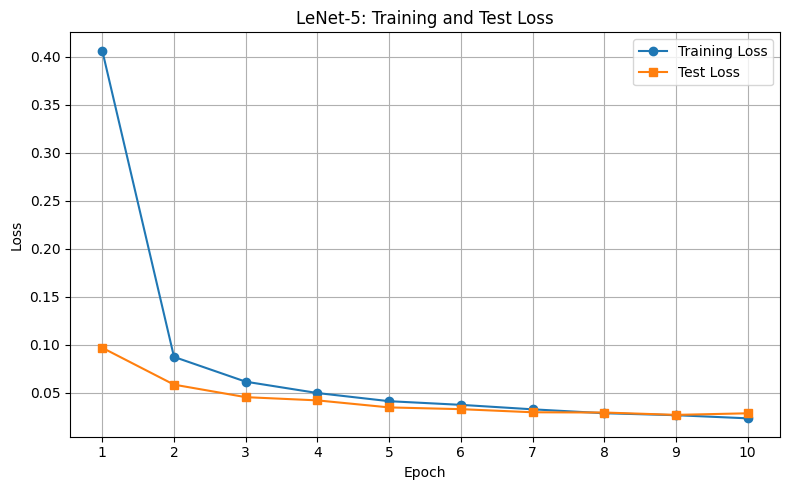

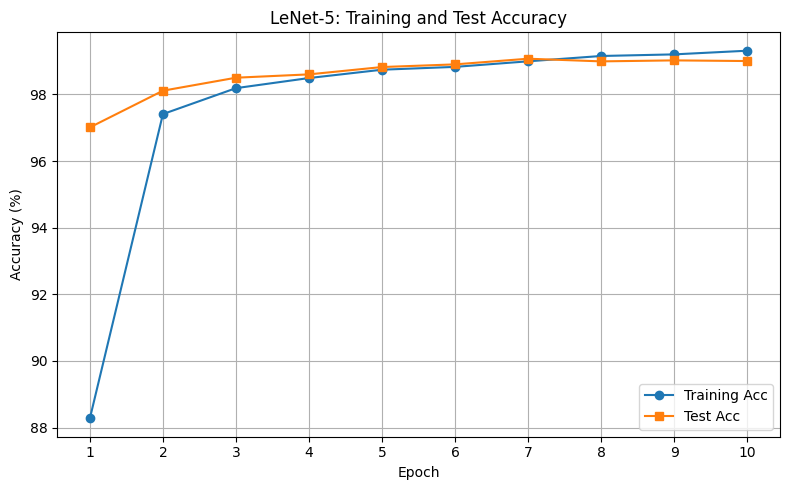

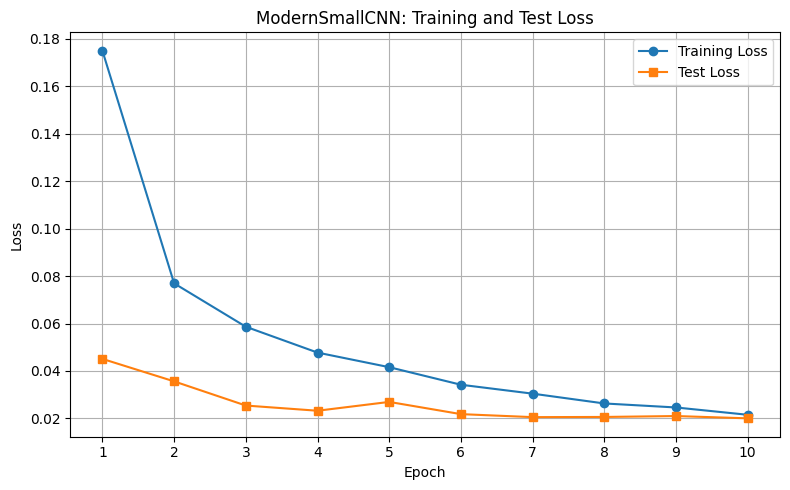

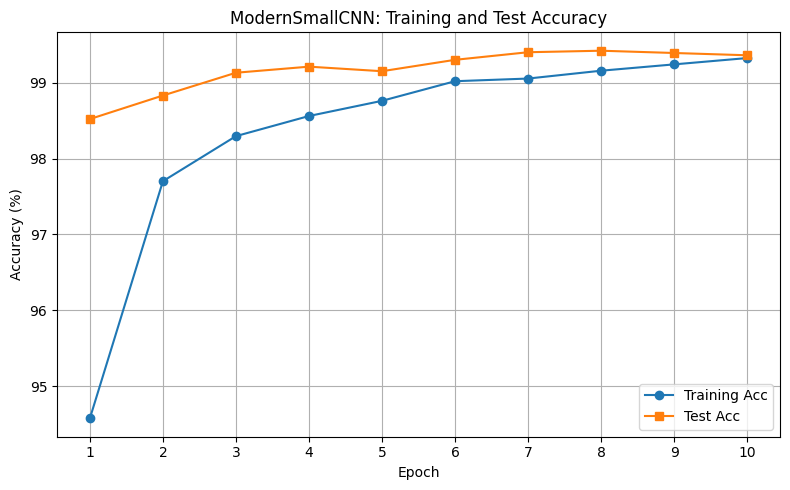

In [126]:
plot_history(lenet_his, 'LeNet-5')
plot_history(cnn_his, 'ModernSmallCNN')

In [127]:

def show_confusion_matrix(model, model_name):

    model.eval()
    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            all_labels.extend(labels.numpy())
            all_predictions.extend(predicted.cpu().numpy())

    cm = confusion_matrix(
        all_labels,
        all_predictions,
        labels=list(range(10))
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=list(range(10))
    )

    fig, ax = plt.subplots(figsize=(8, 8))
    display.plot(ax=ax, cmap='Blues', values_format='d')
    ax.set_title(f'{model_name} Confusion Matrix')
    plt.tight_layout()
    plt.show()

    return cm

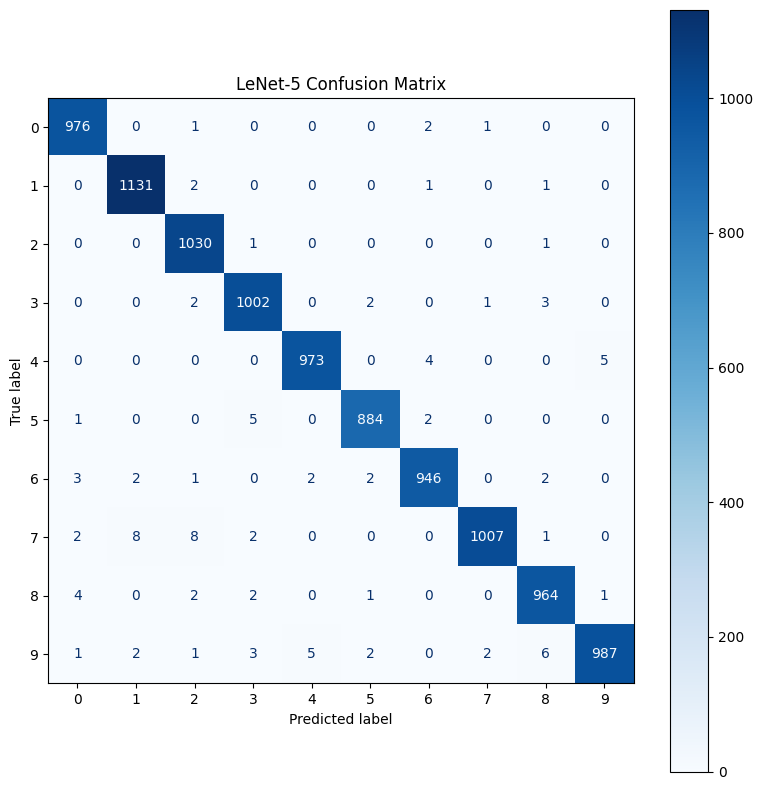

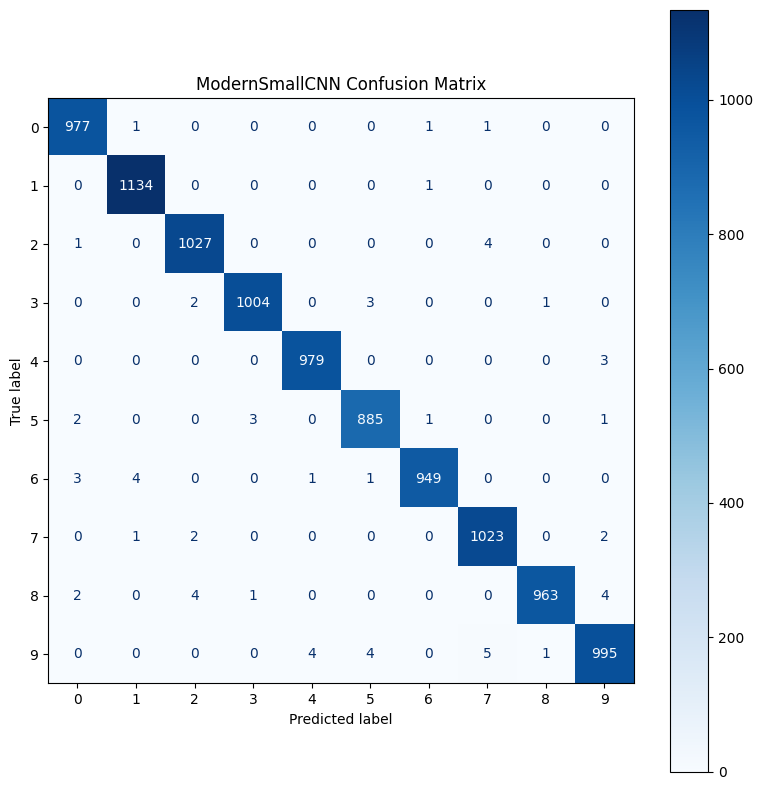

In [128]:
lenet_cm = show_confusion_matrix(model, 'LeNet-5')

cnn_cm = show_confusion_matrix(model_cnn, 'ModernSmallCNN')

## Results and Discussion


*   Both LeNet-5 and ModernSmallCNN were trained on the MNIST dataset for 10 epochs. The training and test loss and accuracy were recorded for each epoch to compare their learning performance.
*   LeNet-5 uses two convolutional layers, Tanh activation, average pooling and fully connected layers for digit classification.

*   ModernSmallCNN uses three convolutional layers, ReLU activation, batch normalization, max pooling, and dropout

* LeNet-5 acheives 99.41% training accuracy and 99.00% test accuracy after 10 epochs while Modern Small CNN acheives 99.78% training accuracy and 99.36% test accuracy after 10 epochs. So, the Modern Small CNN acheives 0.36 percentage points higher test accuracy than LeNet-5.

* The Modern Small CNN obtained a lower test loss (0.0285) than LeNet-5 (0.0200). Also, LeNet-5 has 44,426 parameters, whereas the Modern Small CNN has 897,354 parameters.

* The Modern Small CNN achieved better test performance, while LeNet-5 provided comparable accuracy with significantly fewer parameters.


# Question 3 - Transfer Learning

In [129]:
!wget -q https://download.pytorch.org/tutorial/hymenoptera_data.zip
!unzip -qo hymenoptera_data.zip

In [130]:
data_dir = "hymenoptera_data"
# define transformations
data_transforms = {
    "train": transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ]),

    "val": transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ])
}

image_datasets = {phase: datasets.ImageFolder(
        os.path.join(data_dir, phase),
        transform=data_transforms[phase]
    )
    for phase in ["train", "val"]
}

dataloaders = {
    phase: DataLoader(
        image_datasets[phase],
        batch_size=4,
        shuffle=(phase == "train"),
        num_workers=2
    )
    for phase in ["train", "val"]
}

dataset_sizes = {
    phase: len(image_datasets[phase])
    for phase in ["train", "val"]
}

class_names = image_datasets["train"].classes

print("Classes:", class_names)
print("Dataset sizes:", dataset_sizes)

Classes: ['ants', 'bees']
Dataset sizes: {'train': 244, 'val': 153}


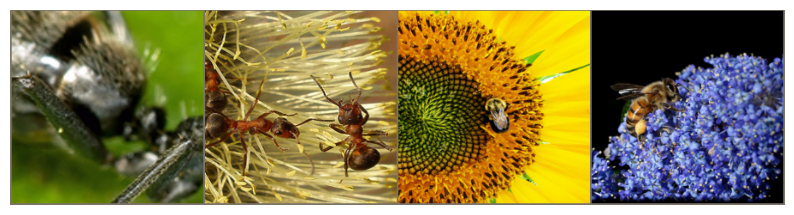

Batch labels: ['ants', 'ants', 'bees', 'bees']


In [131]:
#Visulaize images
inputs, classes = next(iter(dataloaders["train"]))
grid = torchvision.utils.make_grid(inputs, nrow=4)

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

grid = grid * std + mean

plt.figure(figsize=(10, 5))
plt.imshow(grid.permute(1, 2, 0).numpy().clip(0, 1))
plt.axis("off")
plt.show()

print("Batch labels:", [class_names[x] for x in classes])

In [132]:
# Training
def train_model(model, criterion, optimizer, scheduler, epochs=10):
    since = time.time()

    best_model_wts = copy.deepcopy(model.state_dict()) # copy of model parameters
    best_acc = 0.0

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    for epoch in range(epochs):
        for phase in ["train", "val"]:
            if phase == "train":
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == "train"):
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                    _, preds = torch.max(outputs, 1)  #predict class with highest score

                    if phase == "train":
                        loss.backward() #calculate gradients
                        optimizer.step()  #update parameters

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels).item()

            epoch_loss = (
                running_loss / dataset_sizes[phase]
            )
            epoch_acc = (
                running_corrects / dataset_sizes[phase]
            )

            history[f"{phase}_loss"].append(epoch_loss)
            history[f"{phase}_acc"].append(epoch_acc)

            print(
                f"{phase} Loss: {epoch_loss:.4f} "
                f"Acc: {epoch_acc:.4f}"
            )

            if phase == "val" and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(
                    model.state_dict()
                )

        if scheduler is not None:
            scheduler.step()

    elapsed = time.time() - since
    print(f"\nEpoch {epoch + 1}/{epochs} | Training time: {elapsed:.1f} seconds | Best validation accuracy: {best_acc:.4f}")


    model.load_state_dict(best_model_wts)

    return model, history

# Part a - Fine Tunning ResNet18

In [133]:
model_ft = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1) #load architecture with pretrained values

num_ftrs = model_ft.fc.in_features #inputs in fully connected layer

model_ft.fc = nn.Linear(num_ftrs, 2) #replace with two classes
model_ft = model_ft.to(device)

criterion = nn.CrossEntropyLoss()

optimizer_ft = optim.SGD(
    model_ft.parameters(),
    lr=0.001,
    momentum=0.9
)

scheduler_ft = lr_scheduler.StepLR(
    optimizer_ft,
    step_size=7,
    gamma=0.1
)

In [134]:
# Train Fine tunned model
model_ft, history_ft = train_model(
    model_ft,
    criterion,
    optimizer_ft,
    scheduler_ft,
    epochs=10
)

train Loss: 0.6349 Acc: 0.6885
val Loss: 0.5918 Acc: 0.7712
train Loss: 0.4820 Acc: 0.8074
val Loss: 0.6323 Acc: 0.7582
train Loss: 0.6095 Acc: 0.7418
val Loss: 0.2603 Acc: 0.9020
train Loss: 0.4981 Acc: 0.8115
val Loss: 0.3020 Acc: 0.9150
train Loss: 0.4351 Acc: 0.8607
val Loss: 0.2209 Acc: 0.9281
train Loss: 0.5347 Acc: 0.7787
val Loss: 0.3337 Acc: 0.8824
train Loss: 0.3678 Acc: 0.8443
val Loss: 0.4583 Acc: 0.8366
train Loss: 0.3596 Acc: 0.8566
val Loss: 0.3613 Acc: 0.8693
train Loss: 0.3874 Acc: 0.8279
val Loss: 0.3302 Acc: 0.8824
train Loss: 0.2370 Acc: 0.8975
val Loss: 0.3344 Acc: 0.8627

Epoch 10/10 | Training time: 556.2 seconds | Best validation accuracy: 0.9281


# Part b - ResNet18 as a fixed feature extractor

In [135]:
model_fe = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

for param in model_fe.parameters():
    param.requires_grad = False # Freeze all pretrained parameters

# Replace the classifier
num_ftrs = model_fe.fc.in_features
model_fe.fc = nn.Linear(num_ftrs, 2)

model_fe = model_fe.to(device)

criterion = nn.CrossEntropyLoss()

# Optimize only the newly initialized classifier
optimizer_fe = optim.SGD(
    model_fe.fc.parameters(),
    lr=0.001,
    momentum=0.9
)

scheduler_fe = lr_scheduler.StepLR(
    optimizer_fe,
    step_size=7,
    gamma=0.1
)

print("Trainable parameters:")
print(sum(
    p.numel() for p in model_fe.parameters()
    if p.requires_grad
))

Trainable parameters:
1026


In [136]:
#Training
model_fe, history_fe = train_model(
    model_fe,
    criterion,
    optimizer_fe,
    scheduler_fe,
    epochs=10
)

train Loss: 0.7093 Acc: 0.5984
val Loss: 0.2366 Acc: 0.9412
train Loss: 0.4556 Acc: 0.7951
val Loss: 0.1865 Acc: 0.9608
train Loss: 0.5128 Acc: 0.7910
val Loss: 0.1843 Acc: 0.9542
train Loss: 0.5522 Acc: 0.7787
val Loss: 0.3516 Acc: 0.8758
train Loss: 0.4078 Acc: 0.8279
val Loss: 0.1587 Acc: 0.9477
train Loss: 0.5363 Acc: 0.8033
val Loss: 0.4982 Acc: 0.7908
train Loss: 0.4205 Acc: 0.8566
val Loss: 0.2074 Acc: 0.9477
train Loss: 0.3295 Acc: 0.8648
val Loss: 0.1759 Acc: 0.9477
train Loss: 0.2795 Acc: 0.8648
val Loss: 0.1820 Acc: 0.9542
train Loss: 0.4183 Acc: 0.8197
val Loss: 0.2246 Acc: 0.9346

Epoch 10/10 | Training time: 247.0 seconds | Best validation accuracy: 0.9608


Plot training and validation results

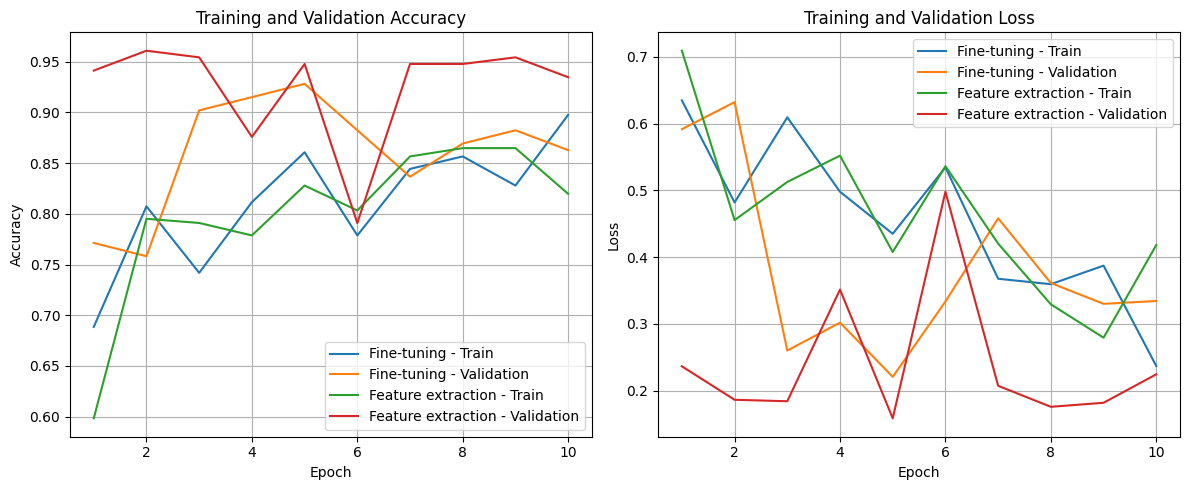

In [137]:
def plot_history(history_ft, history_fe):
    epochs = range(1, len(history_ft["train_acc"]) + 1)

    plt.figure(figsize=(12, 5))

    # Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history_ft["train_acc"],
             label="Fine-tuning - Train")
    plt.plot(epochs, history_ft["val_acc"],
             label="Fine-tuning - Validation")
    plt.plot(epochs, history_fe["train_acc"],
             label="Feature extraction - Train")
    plt.plot(epochs, history_fe["val_acc"],
             label="Feature extraction - Validation")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Training and Validation Accuracy")
    plt.legend()
    plt.grid(True)

    # Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history_ft["train_loss"],
             label="Fine-tuning - Train")
    plt.plot(epochs, history_ft["val_loss"],
             label="Fine-tuning - Validation")
    plt.plot(epochs, history_fe["train_loss"],
             label="Feature extraction - Train")
    plt.plot(epochs, history_fe["val_loss"],
             label="Feature extraction - Validation")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training and Validation Loss")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

plot_history(history_ft, history_fe)


Fine-tuning
Validation accuracy: 0.9281
Validation accuracy: 92.81%

Classification report:
              precision    recall  f1-score   support

        ants       0.95      0.89      0.92        70
        bees       0.91      0.96      0.94        83

    accuracy                           0.93       153
   macro avg       0.93      0.92      0.93       153
weighted avg       0.93      0.93      0.93       153



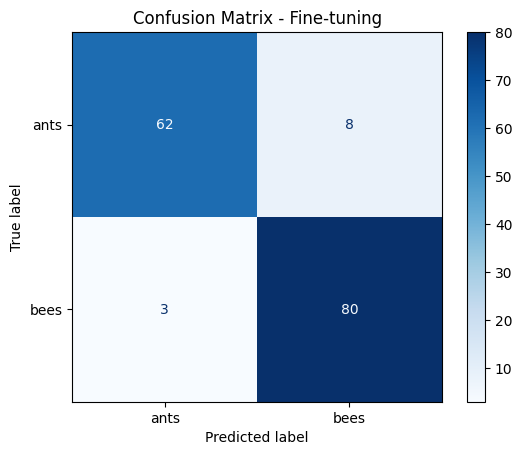


Feature extraction
Validation accuracy: 0.9608
Validation accuracy: 96.08%

Classification report:
              precision    recall  f1-score   support

        ants       0.94      0.97      0.96        70
        bees       0.98      0.95      0.96        83

    accuracy                           0.96       153
   macro avg       0.96      0.96      0.96       153
weighted avg       0.96      0.96      0.96       153



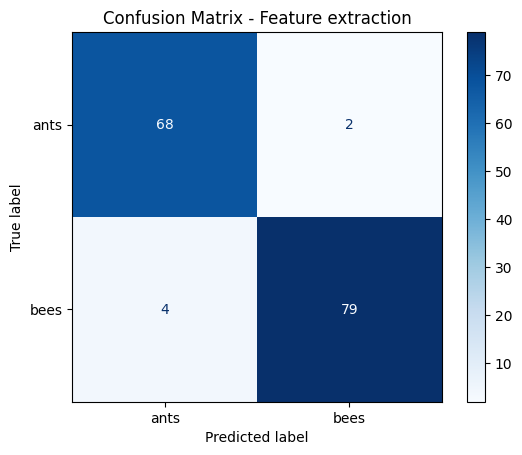

In [138]:
#Evaluation
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

def evaluate_model(model, model_name):
    model.eval()

    all_labels = []
    all_preds = []

    with torch.no_grad():
        for inputs, labels in dataloaders["val"]:
            inputs = inputs.to(device)

            outputs = model(inputs)
            preds = outputs.argmax(dim=1).cpu()

            all_labels.extend(labels.numpy())
            all_preds.extend(preds.numpy())

    accuracy = accuracy_score(all_labels, all_preds)

    print(f"\n{model_name}")
    print(f"Validation accuracy: {accuracy:.4f}")
    print(f"Validation accuracy: {accuracy * 100:.2f}%")

    print("\nClassification report:")
    print(classification_report(
        all_labels,
        all_preds,
        labels=[0, 1],
        target_names=class_names,
        zero_division=0
    ))

    cm = confusion_matrix(
        all_labels, all_preds, labels=[0, 1]
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    ).plot(cmap="Blues", values_format="d")

    plt.title(f"Confusion Matrix - {model_name}")
    plt.show()

    return accuracy, cm


acc_ft, cm_ft = evaluate_model(
    model_ft, "Fine-tuning"
)

acc_fe, cm_fe = evaluate_model(
    model_fe, "Feature extraction"
)

In [139]:
#results
import pandas as pd

# Create a training evaluation dataset without random augmentation
train_eval_dataset = datasets.ImageFolder(
    os.path.join(data_dir, "train"),
    transform=data_transforms["val"]
)

train_eval_loader = DataLoader(
    train_eval_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2
)

# Evaluate loss and accuracy
def evaluate_model(model, loader):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * inputs.size(0)
            _, predictions = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    avg_loss = running_loss / total
    accuracy = 100 * correct / total

    return avg_loss, accuracy


# Evaluate both restored best models
ft_train_loss, ft_train_acc = evaluate_model(
    model_ft, train_eval_loader
)
ft_val_loss, ft_val_acc = evaluate_model(
    model_ft, dataloaders["val"]
)

fe_train_loss, fe_train_acc = evaluate_model(
    model_fe, train_eval_loader
)
fe_val_loss, fe_val_acc = evaluate_model(
    model_fe, dataloaders["val"]
)

# Display the comparison
results = pd.DataFrame({
    "Method": ["Fine-tuning", "Feature extraction"],
    "Training Accuracy (%)": [ft_train_acc, fe_train_acc],
    "Validation Accuracy (%)": [ft_val_acc, fe_val_acc],
    "Training Loss": [ft_train_loss, fe_train_loss],
    "Validation Loss": [ft_val_loss, fe_val_loss]
})

print(results.round(4).to_string(index=False))

            Method  Training Accuracy (%)  Validation Accuracy (%)  Training Loss  Validation Loss
       Fine-tuning                97.9508                  92.8105         0.0484           0.2209
Feature extraction                95.9016                  96.0784         0.1132           0.1865


# Results and Discussions

* Here, the ResNet18 pretrained on ImageNet1K was used to classify the Hymenoptera dataset into two classes ants and bees.
* Fine-tunning and feature extraction both models are used to train both models for 10 epochs using SGD with learning rate 0.001 and momentum of 0.9.

* In fine-tuning all ResNet18 layers were trainable, allowing pretrained features to adapt to the ants-and-bees dataset.

* In feature extraction the pretrained layers were frozen and only the final fully connected layer was trained. So,It reduces the number of trainable parameters to 1,026.

* Since prtrained layers are not update, feature extraction generally needs less computation.

* Feature extraction achieved a higher best validation accuracy of 96.08%, compared with 92.81% for fine-tuning, indicating better validation performance in this experiment.

* Feature extraction performed better on the validation dataset by achieving higher validation accuracy and lower validation loss. Fine-tuning achieved better training performance but didn't have better validation results. Therefore, feature extraction was the better performing approach in this experiment, while also requiring fewer trainable parameters and generally less computation.